In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

plt.rcParams["figure.figsize"] = (8,6)

In [2]:
hf = h5py.File('../Shared/gammaray_lab4.h5', 'r')

Viewing data column headers

In [3]:
hf.keys()

<KeysViewHDF5 ['data']>

Move data into array

In [4]:
data = np.array(hf.get('data'))
print(hf.keys())

<KeysViewHDF5 ['data']>


In [5]:
np.shape(data)

(4, 25920001)

In [6]:
data[:,0]

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

In [7]:
hf.close()

## Problem

In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

As with most data, there are 'features.' Your lab instructor has helpfully incorporated the meta-data into your data file.

1. Examine the data. The columns are time (in gps seconds), Solar phase (deg) showing the position of the sun relative to the orbit, Earth longitude (deg) giving the position of the spacecraft relative to the ground, and particle counts. Make a few plots, generally exploring your data and making sure you understand it. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().

(25920001,)
(25920001,)
[9.40680016e+08 9.40680016e+08 9.40680016e+08 ... 9.43272016e+08
 9.43272016e+08 9.43272016e+08]
[10.  8.  7. ...  8. 11. 12.]
[45.         45.00666667 45.01333334 ... 44.98666666 44.99333333
 45.        ]
mean is 7.1714


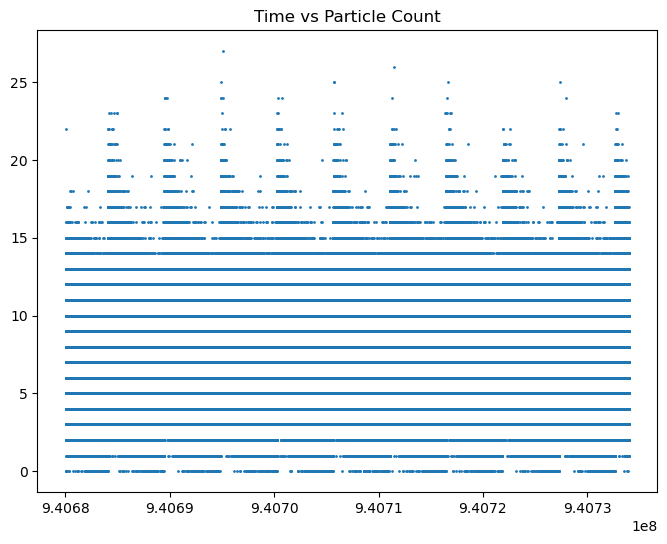

TypeError: scatter_plot() missing 2 required positional arguments: 'y' and 'title'

In [131]:
def scatter_plot(x, y, title):
    fig, ax = plt.subplots(1, 1)
    ax.scatter(x, y, s=1)
    ax.set_title(title)
    plt.show()

np.shape(data)
data_records = np.shape(data[-1])
data_records

time = data[0,:]
solar_phase = data[1,:]
earth_longitude = data[2,:]
particle_count = data[3,:]
print(time.shape)
print(particle_count.shape)
print(time)
print(particle_count)
print(earth_longitude)

mean_first = np.mean(particle_count[:10000])
print(f'mean is {mean_first}')

scatter_plot(scatter_plot(time[:540000], particle_count[:540000], "Time vs Particle Count"))

mean is 8.7949


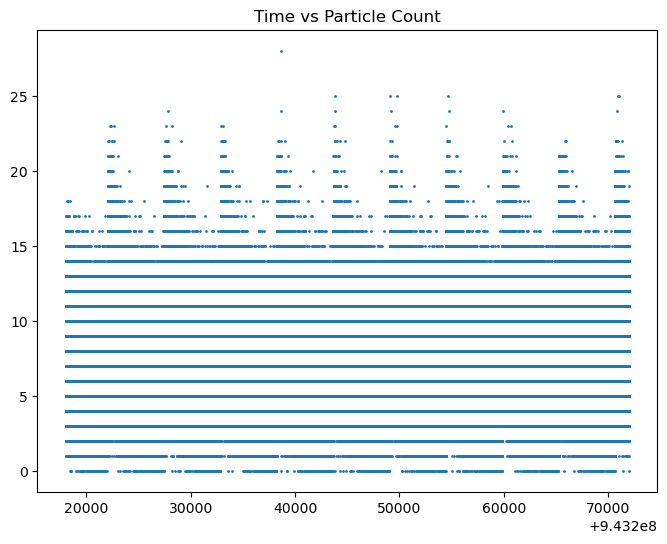

TypeError: scatter_plot() missing 2 required positional arguments: 'y' and 'title'

In [132]:
mean_last = np.mean(particle_count[-10000:])
print(f'mean is {mean_last}')

scatter_plot(scatter_plot(time[-540000:], particle_count[-540000:], "Time vs Particle Count"))

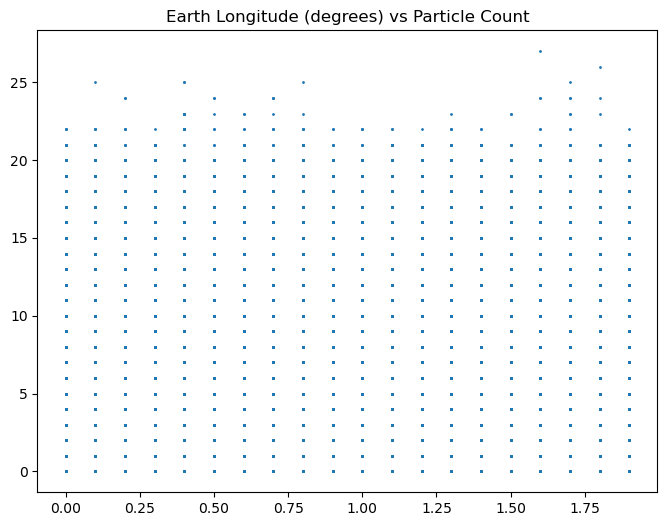

TypeError: scatter_plot() missing 2 required positional arguments: 'y' and 'title'

In [91]:
time_fold = time % 2
scatter_plot(scatter_plot(time_fold[:540000], particle_count[:540000], "Earth Longitude (degrees) vs Particle Count"))

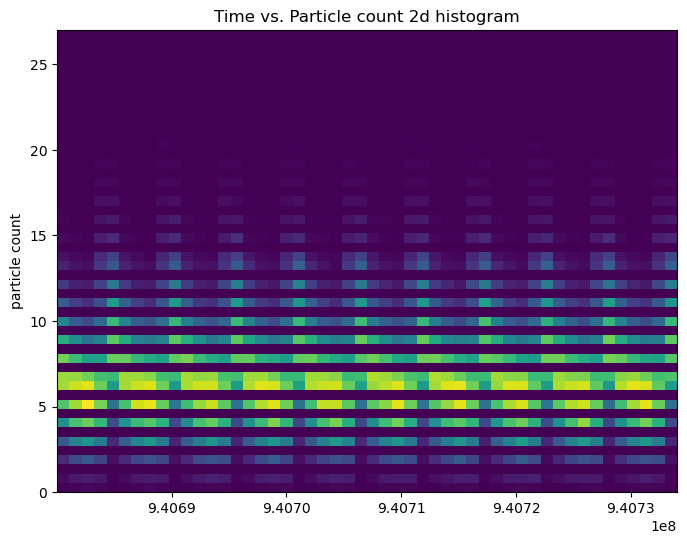

In [92]:
def histogram_plot(x, y, title):
    fig, ax = plt.subplots(1, 1)
    plt.hist2d(x, y, bins=50)
    ax.set_title(title)
    ax.set_ylabel("particle count")
    plt.show()

histogram_plot(time[:540000], particle_count[:540000], "Time vs. Particle count 2d histogram")

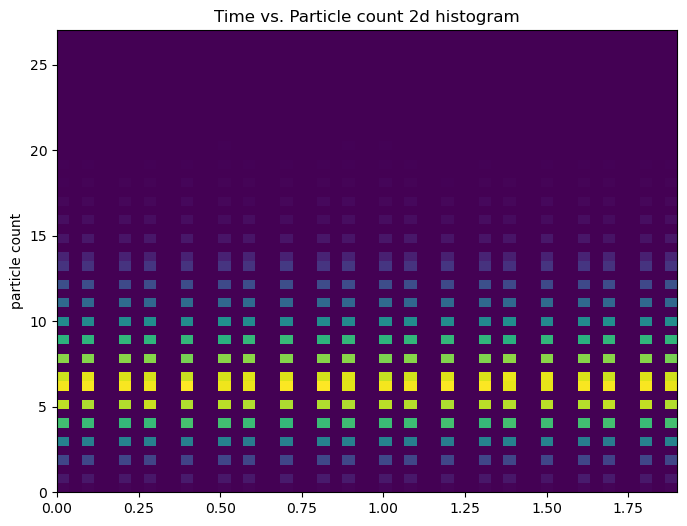

In [93]:
histogram_plot(time_fold[:540000], particle_count[:540000], "Time vs. Particle count 2d histogram")

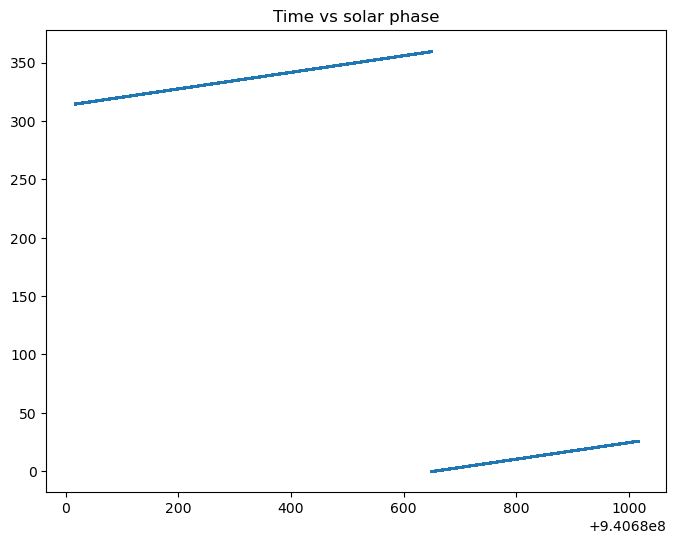

TypeError: scatter_plot() missing 2 required positional arguments: 'y' and 'title'

In [73]:
scatter_plot(scatter_plot(time[:10000], solar_phase[:10000], "Time vs solar phase"))

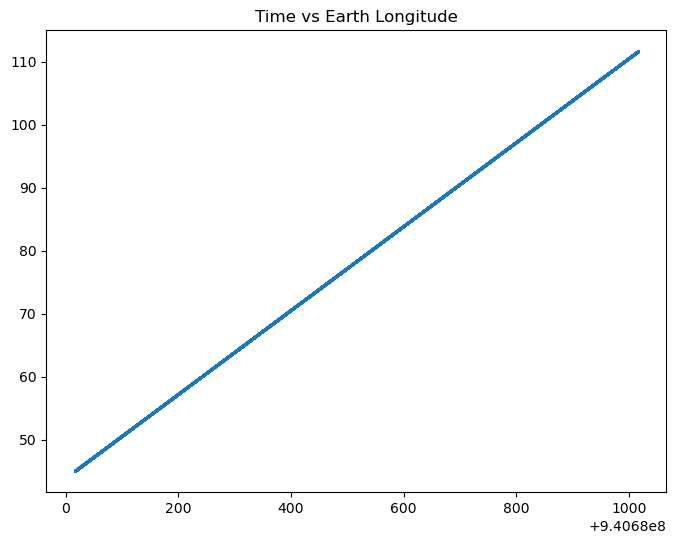

TypeError: scatter_plot() missing 2 required positional arguments: 'y' and 'title'

In [94]:
scatter_plot(scatter_plot(time[:10000], earth_longitude[:10000], "Time vs Earth Longitude"))

### When you plot time vs. Earth longitude and time vs. Solar phase, you see a linear relationship, as expected due to the predictable and linear movement of the Sun and Earth.  

### When you plot time vs. particle count, you can see a periodic spike in the particle counts. This indicates a periodic signal contamination within the data. To create the background distribution, we should use a Poissonian distribution to account for the discrete, positive gamma ray burst counts. The function will be centered around the mean of the particle counts.

# Problem 3

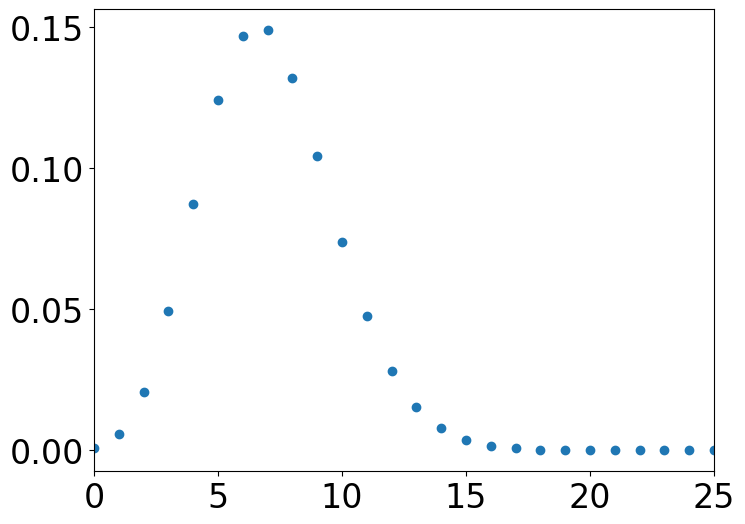

In [130]:
particle_count_mean = np.mean(particle_count)
k = np.arange(0,100,1)

fig, ax = plt.subplots(1, 1)
plt.tick_params(labelsize = 24)
plt.xlim([0, 25])
plt.scatter(k, stats.poisson.pmf(k = k, mu = particle_count_mean))
plt.show()

### Comparing model to real data